# Analysis Results Summary

This notebook presents the results of the MLLM-based usability analysis conducted on several configurator applications. The analysis evaluated each application against a set of predefined usability criteria and categorized issues by their severity.

The results are summarized through:
1. Overall severity distribution across all apps and criteria.
2. Severity distribution per configurator application.
3. Severity distribution per usability criterion.
4. Analysis of the time taken for the evaluation requests.


In [1]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

def load_analysis_results(file_name):
    """Load analysis results from a JSON line-separated file."""
    with open(file_name, "r") as f:
        records = [json.loads(line) for line in f]
    return records

# Load data
analysis_report = load_analysis_results(os.path.join("report", "analysis_report.json"))
analysis_report_df = pd.DataFrame(analysis_report)

# Show a preview of the data
analysis_report_df.head()

,criterion,severity,description,recommendation,app_id,criterion_id,request_duration
0,Customized options,Minor Issue,"The configurator presents a single, comprehens...",Implement an initial step or a toggle that all...,APP1,C1,19.4615
1,Organized configuration space,No Issue,NaN,NaN,APP1,C2,19.0705
2,Availability of options,Major Issue,"After adding a configured tie to the cart, all...",Implement state persistence for the configurat...,APP1,C3,17.8620
3,Auto-completion,Minor Issue,The configurator requires users to manually se...,Consider adding a 'Apply Standard Options' but...,APP1,C4,27.6735
4,Variant comparison,Major Issue,The configurator does not offer any functional...,Implement a 'Save Design' or 'Add to Wishlist'...,APP1,C5,16.4928


## 1. Overall Severity Distribution

The following table shows the total count of results for each severity level across all evaluated applications and criteria.


In [2]:
analysis_report_df.groupby("severity").agg({"severity": "count"}).rename(columns={"severity": "count"}).sort_values("count", ascending=False)

,count
severity,
No Issue,140
Major Issue,75
Minor Issue,73


## 2. Results per Configurator Application

The analysis was performed on several configurator applications. The following plot shows the distribution of issue severities for each application, identified by its ID.


<Figure size 600x400 with 0 Axes>

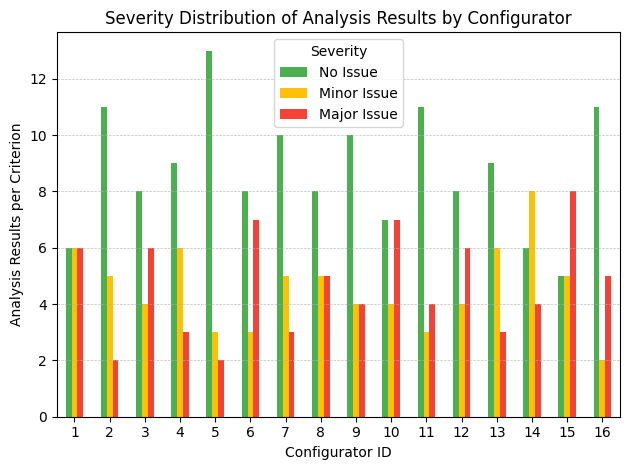

In [3]:
df_app = analysis_report_df.copy()
df_app["app_id_int"] = df_app["app_id"].apply(lambda x: int(x[3:]))
df_app = df_app.sort_values("app_id_int")

# Create a pivot table for the count of each severity by app_id
severity_counts = df_app.pivot_table(
    index='app_id_int',
    columns='severity',
    values='criterion',
    aggfunc='count',
    fill_value=0
)

# Reorder the columns for consistent display
severity_order = ['No Issue', 'Minor Issue', 'Major Issue']
# Filter columns to only those that exist in the data
available_severities = [s for s in severity_order if s in severity_counts.columns]
severity_counts = severity_counts[available_severities]

# Create the bar plot with matplotlib
plt.figure(figsize=(6, 4))
severity_counts.plot(kind='bar', color=['#4CAF50', '#FFC107', '#F44336'])

# Customize the plot
plt.title('Severity Distribution of Analysis Results by Configurator')
plt.xlabel('Configurator ID')
plt.ylabel('Analysis Results per Criterion')
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.8)
plt.legend(title='Severity')

plt.tight_layout()
plt.savefig(os.path.join("results", "severity_by_configurator.png"), dpi=800)
plt.show()

## 3. Results per Usability Criterion

Each application was evaluated against specific usability criteria. The following visualization summarizes the severity of issues found across all applications for each criterion.


<Figure size 600x400 with 0 Axes>

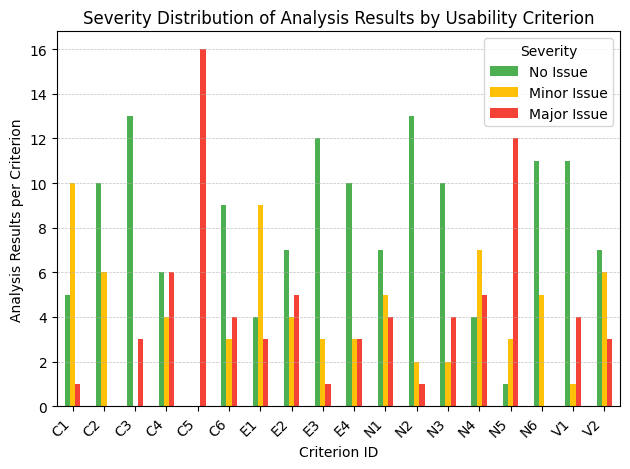

In [4]:
df_crit = analysis_report_df.copy().sort_values("criterion_id")

# Create a pivot table for the count of each severity by criterion_id
severity_by_criterion = df_crit.pivot_table(
    index='criterion_id',
    columns='severity',
    values='app_id',
    aggfunc='count',
    fill_value=0
)

# Reorder the columns for consistent display
severity_order = ['No Issue', 'Minor Issue', 'Major Issue']
available_severities = [s for s in severity_order if s in severity_by_criterion.columns]
severity_by_criterion = severity_by_criterion[available_severities]

# Create the bar plot
plt.figure(figsize=(6, 4))
ax = severity_by_criterion.plot(kind='bar', color=['#4CAF50', '#FFC107', '#F44336'])

# Customize the plot
plt.title('Severity Distribution of Analysis Results by Usability Criterion')
plt.xlabel('Criterion ID')
plt.ylabel('Analysis Results per Criterion')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.8)
plt.legend(title='Severity')
plt.tight_layout()

# Save the figure
plt.savefig(os.path.join("results", "severity_by_criterion.png"), dpi=800)
plt.show()

## 4. Analysis Duration

We analyzed the time taken for the evaluation requests. Below are the statistics for both individual criterion requests and the total time per application.


In [6]:
duration_stats = pd.Series({
    "Mean (per request)": analysis_report_df["request_duration"].mean(),
    "Median (per request)": analysis_report_df["request_duration"].median(),
    "Min (per request)": analysis_report_df["request_duration"].min(),
    "Max (per request)": analysis_report_df["request_duration"].max(),
}).to_frame("Duration (s)").round(1)

app_total_duration = analysis_report_df.groupby(["app_id"]).agg({"request_duration": "sum"})
app_stats = pd.Series({
    "Mean (total per app)": app_total_duration["request_duration"].mean(),
    "Median (total per app)": app_total_duration["request_duration"].median(),
    "Min (total per app)": app_total_duration["request_duration"].min(),
    "Max (total per app)": app_total_duration["request_duration"].max(),
}).to_frame("Duration (s)").round(1)

pd.concat([duration_stats, app_stats])


,Duration (s)
Mean (per request),14.4
Median (per request),12.1
Min (per request),3.4
Max (per request),52.8
Mean (total per app),258.4
Median (total per app),237.4
Min (total per app),135.6
Max (total per app),636.7
